# False Positive Analysis (Objective 2)

This notebook implements Objective 2: extract and analyze false positive (FP) predictions.

**Goal**: Evaluate the rate and confidence distribution of FPs at different thresholds.
**Method**: 
1. Run inference on the test set
2. Match predictions to ground-truth annotations (IoU threshold)
3. Classify each prediction as TP (true positive) or FP (false positive)
4. Analyze FP confidence distribution and count at clinically relevant thresholds

In [21]:
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')

project_root = Path("/content/drive/MyDrive/Spark_2026_Team_Rwanda_Main_Folder/Practicum_Main_Project/")
dataset_root = project_root / "model_b"
clean_root = dataset_root

model_checkpoint = project_root / "model_checkpoints" / "model_b_best.pt"

print(f"Dataset: {dataset_root}")
print(f"Dataset exists: {dataset_root.exists()}")
print(f"Model: {model_checkpoint}")
print(f"Model exists: {model_checkpoint.exists()}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset: /content/drive/MyDrive/new_spark_capstone/Spark_Capstone.v2-augmented.parasite_only
Dataset exists: True
Model: /content/drive/MyDrive/new_spark_capstone/model_checkpoints/model_a_best.pt
Model exists: True


In [22]:
# Cell 2: Install packages
import subprocess
import sys

packages = ['ultralytics', 'pandas', 'numpy', 'scipy']
for pkg in packages:
    print(f"Installing {pkg}...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

print("All packages installed!")

Installing ultralytics...
Installing pandas...
Installing numpy...
Installing scipy...
All packages installed!


In [23]:
# Cell 3: Load ground-truth annotations from test set
from pathlib import Path
import numpy as np

def parse_yolo_label(label_path, img_width=2048, img_height=2048):
    """
    Parse YOLO format label file and return box coordinates.
    YOLO format: class_id x_center y_center width height (normalized 0-1)
    Returns: list of [x_min, y_min, x_max, y_max, class_id] in pixel coords
    """
    boxes = []
    if not label_path.exists():
        return boxes
    
    with open(label_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 5:
                class_id = int(parts[0])
                x_center = float(parts[1]) * img_width
                y_center = float(parts[2]) * img_height
                width = float(parts[3]) * img_width
                height = float(parts[4]) * img_height
                
                x_min = x_center - width / 2
                y_min = y_center - height / 2
                x_max = x_center + width / 2
                y_max = y_center + height / 2
                
                boxes.append([x_min, y_min, x_max, y_max, class_id])
    
    return boxes

# Load ground truth from test set
test_labels_dir = dataset_root / "test" / "labels"
test_label_files = sorted(test_labels_dir.glob("*.txt"))

ground_truth = {}
for label_file in test_label_files:
    image_id = label_file.stem
    boxes = parse_yolo_label(label_file)
    ground_truth[image_id] = boxes

print(f"Loaded ground truth for {len(ground_truth)} test images")
print(f"Total ground truth boxes: {sum(len(boxes) for boxes in ground_truth.values())}")

Loaded ground truth for 412 test images
Total ground truth boxes: 2374


In [24]:
# Cell 4: Run inference on test set
from ultralytics import YOLO
from pathlib import Path

# Load trained model
model = YOLO(str(model_checkpoint))

test_images_dir = dataset_root / "test" / "images"
print(f"Running inference on {test_images_dir}...")

# Run predictions with low confidence threshold to capture all detections
results = model.predict(
    source=str(test_images_dir),
    save=False,
    conf=0.1,  # Low threshold to capture potential FPs
    verbose=False
)

print(f"Inference completed for {len(results)} images")

Running inference on /content/drive/MyDrive/new_spark_capstone/Spark_Capstone.v2-augmented.parasite_only/test/images...
Inference completed for 412 images


In [25]:
# Cell 5: Compute IoU for TP/FP classification
import numpy as np
import pandas as pd

def compute_iou(box1, box2):
    """
    Compute Intersection over Union (IoU) between two boxes.
    box format: [x_min, y_min, x_max, y_max]
    """
    x_min_inter = max(box1[0], box2[0])
    y_min_inter = max(box1[1], box2[1])
    x_max_inter = min(box1[2], box2[2])
    y_max_inter = min(box1[3], box2[3])
    
    if x_max_inter < x_min_inter or y_max_inter < y_min_inter:
        return 0.0
    
    inter_area = (x_max_inter - x_min_inter) * (y_max_inter - y_min_inter)
    box1_area = (box1[2] - box1[0]) * (box1[3] - box1[1])
    box2_area = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union_area = box1_area + box2_area - inter_area
    
    if union_area == 0:
        return 0.0
    
    return inter_area / union_area

# Classify predictions as TP or FP
predictions = []
iou_threshold = 0.5

for r in results:
    image_id = Path(r.path).stem
    gt_boxes = ground_truth.get(image_id, [])
    
    # Track which ground truth boxes have been matched
    gt_matched = [False] * len(gt_boxes)
    
    for box in r.boxes:
        conf = float(box.conf[0])
        pred_box = [
            float(box.xyxy[0][0]),  # x_min
            float(box.xyxy[0][1]),  # y_min
            float(box.xyxy[0][2]),  # x_max
            float(box.xyxy[0][3])   # y_max
        ]
        
        # Find best matching ground truth box
        best_iou = 0
        best_gt_idx = -1
        
        for gt_idx, gt_box in enumerate(gt_boxes):
            if not gt_matched[gt_idx]:  # Only match unmatched GTs
                iou = compute_iou(pred_box, gt_box[:4])
                if iou > best_iou:
                    best_iou = iou
                    best_gt_idx = gt_idx
        
        # Classify as TP or FP
        is_tp = best_iou >= iou_threshold
        if is_tp and best_gt_idx >= 0:
            gt_matched[best_gt_idx] = True
        
        predictions.append({
            'image_id': image_id,
            'x_center': float(box.xywh[0][0]),
            'y_center': float(box.xywh[0][1]),
            'confidence': conf,
            'is_tp': is_tp,
            'is_fp': not is_tp,
            'best_iou': best_iou
        })

df_predictions = pd.DataFrame(predictions)
print(f"Total predictions: {len(df_predictions)}")
print(f"True Positives: {df_predictions['is_tp'].sum()}")
print(f"False Positives: {df_predictions['is_fp'].sum()}")
print(f"\nFirst few predictions:")
print(df_predictions.head(10))

Total predictions: 4307
True Positives: 2007
False Positives: 2300

First few predictions:
                                            image_id     x_center  \
0  id_021o79u9zs_jpg.rf.25e86ebb675c004b4aed47697...  1048.835571   
1  id_021o79u9zs_jpg.rf.25e86ebb675c004b4aed47697...   373.325073   
2  id_021o79u9zs_jpg.rf.25e86ebb675c004b4aed47697...   417.109680   
3  id_021o79u9zs_jpg.rf.25e86ebb675c004b4aed47697...  1658.546631   
4  id_021o79u9zs_jpg.rf.25e86ebb675c004b4aed47697...  1132.115967   
5  id_021o79u9zs_jpg.rf.25e86ebb675c004b4aed47697...  1655.645630   
6  id_0fdars2kkw_jpg.rf.c10df73ab7c63acff59e1c9b7...  1627.780151   
7  id_0fdars2kkw_jpg.rf.c10df73ab7c63acff59e1c9b7...   657.302612   
8  id_0fdars2kkw_jpg.rf.c10df73ab7c63acff59e1c9b7...  1627.546143   
9  id_0fdars2kkw_jpg.rf.c10df73ab7c63acff59e1c9b7...  1528.670532   

      y_center  confidence  is_tp  is_fp  best_iou  
0   844.619141    0.598823   True  False  0.751470  
1   865.350342    0.345409  False   True  0

In [26]:
# Cell 6: Analyze FP distribution across confidence thresholds
import pandas as pd

# Define confidence thresholds
thresholds = [0.1, 0.25, 0.5, 0.75, 0.9]

print("\n" + "="*60)
print("FP Analysis at Different Confidence Thresholds")
print("="*60)

summary_data = []
for thresh in thresholds:
    above_thresh = df_predictions[df_predictions['confidence'] >= thresh]
    fps_above = above_thresh['is_fp'].sum()
    tps_above = above_thresh['is_tp'].sum()
    total_above = len(above_thresh)
    
    if total_above > 0:
        precision = tps_above / total_above
        fp_rate = fps_above / total_above
    else:
        precision = 1.0
        fp_rate = 0.0
    
    summary_data.append({
        'confidence_threshold': thresh,
        'total_predictions': total_above,
        'true_positives': tps_above,
        'false_positives': fps_above,
        'precision': precision,
        'fp_rate': fp_rate
    })
    
    print(f"\nThreshold: {thresh}")
    print(f"  Total predictions: {total_above}")
    print(f"  TP: {tps_above}, FP: {fps_above}")
    print(f"  Precision: {precision:.4f}")
    print(f"  FP Rate: {fp_rate:.4f}")

df_summary = pd.DataFrame(summary_data)

# Export summary
summary_path = project_root / "fp_analysis_summary.csv"
df_summary.to_csv(summary_path, index=False)
print(f"\nSummary exported to: {summary_path}")


FP Analysis at Different Confidence Thresholds

Threshold: 0.1
  Total predictions: 4307
  TP: 2007, FP: 2300
  Precision: 0.4660
  FP Rate: 0.5340

Threshold: 0.25
  Total predictions: 2721
  TP: 1715, FP: 1006
  Precision: 0.6303
  FP Rate: 0.3697

Threshold: 0.5
  Total predictions: 859
  TP: 746, FP: 113
  Precision: 0.8685
  FP Rate: 0.1315

Threshold: 0.75
  Total predictions: 1
  TP: 1, FP: 0
  Precision: 1.0000
  FP Rate: 0.0000

Threshold: 0.9
  Total predictions: 0
  TP: 0, FP: 0
  Precision: 1.0000
  FP Rate: 0.0000

Summary exported to: /content/drive/MyDrive/new_spark_capstone/fp_analysis_summary.csv


In [27]:
# Cell 7: Detailed FP confidence statistics
print("\n" + "="*60)
print("False Positive Confidence Distribution")
print("="*60)

fps_only = df_predictions[df_predictions['is_fp']]
tps_only = df_predictions[df_predictions['is_tp']]

print(f"\nFalse Positives (n={len(fps_only)}):")
print(f"  Mean confidence: {fps_only['confidence'].mean():.4f}")
print(f"  Median confidence: {fps_only['confidence'].median():.4f}")
print(f"  Std dev: {fps_only['confidence'].std():.4f}")
print(f"  Min: {fps_only['confidence'].min():.4f}")
print(f"  Max: {fps_only['confidence'].max():.4f}")

print(f"\nTrue Positives (n={len(tps_only)}):")
print(f"  Mean confidence: {tps_only['confidence'].mean():.4f}")
print(f"  Median confidence: {tps_only['confidence'].median():.4f}")
print(f"  Std dev: {tps_only['confidence'].std():.4f}")
print(f"  Min: {tps_only['confidence'].min():.4f}")
print(f"  Max: {tps_only['confidence'].max():.4f}")

# Export detailed predictions for further analysis
predictions_path = project_root / "predictions_with_tp_fp_labels.csv"
df_predictions.to_csv(predictions_path, index=False)
print(f"\nDetailed predictions exported to: {predictions_path}")


False Positive Confidence Distribution

False Positives (n=2300):
  Mean confidence: 0.2526
  Median confidence: 0.2203
  Std dev: 0.1309
  Min: 0.1000
  Max: 0.7134

True Positives (n=2007):
  Mean confidence: 0.4291
  Median confidence: 0.4579
  Std dev: 0.1439
  Min: 0.1009
  Max: 0.7732

Detailed predictions exported to: /content/drive/MyDrive/new_spark_capstone/predictions_with_tp_fp_labels.csv


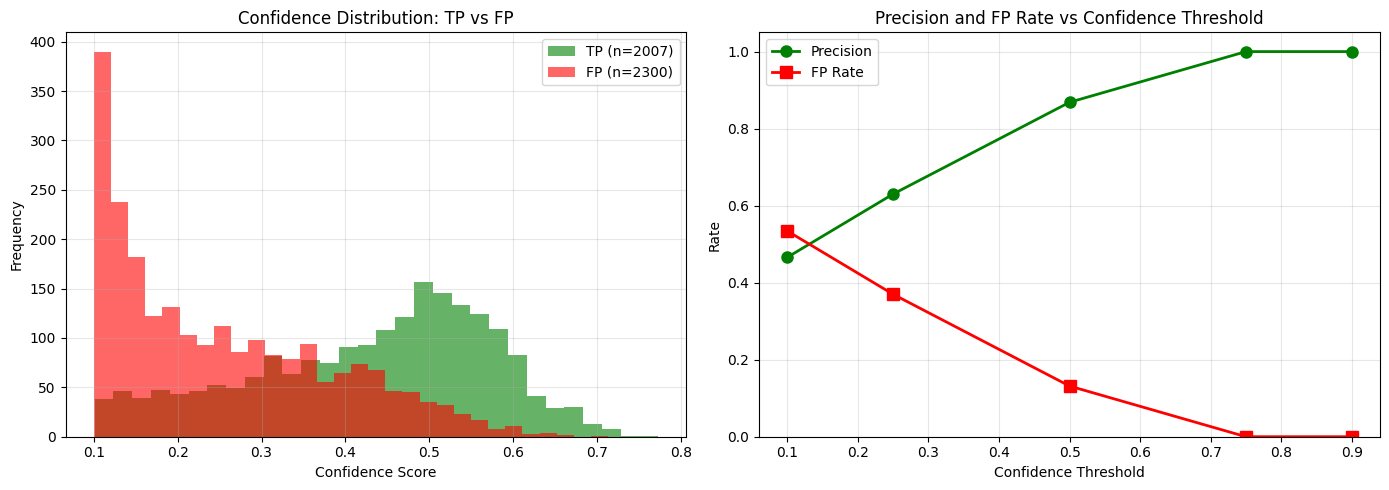

Visualization saved to: fp_analysis_visualization.png


In [28]:
# Cell 8: Visualize FP confidence distribution
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Confidence distribution for TP vs FP
ax = axes[0]
ax.hist(tps_only['confidence'], bins=30, alpha=0.6, label=f'TP (n={len(tps_only)})', color='green')
ax.hist(fps_only['confidence'], bins=30, alpha=0.6, label=f'FP (n={len(fps_only)})', color='red')
ax.set_xlabel('Confidence Score')
ax.set_ylabel('Frequency')
ax.set_title('Confidence Distribution: TP vs FP')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: Precision and FP rate vs threshold
ax = axes[1]
ax.plot(df_summary['confidence_threshold'], df_summary['precision'], 'g-o', label='Precision', linewidth=2, markersize=8)
ax.plot(df_summary['confidence_threshold'], df_summary['fp_rate'], 'r-s', label='FP Rate', linewidth=2, markersize=8)
ax.set_xlabel('Confidence Threshold')
ax.set_ylabel('Rate')
ax.set_title('Precision and FP Rate vs Confidence Threshold')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim([0, 1.05])

plt.tight_layout()
plt.savefig(project_root / 'fp_analysis_visualization.png', dpi=100)
plt.show()

print("Visualization saved to: fp_analysis_visualization.png")